##Iris Flower Classification


<b> Import Libraries

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.feature_selection import f_classif

<b>Load dataset

In [3]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = pd.Categorical.from_codes(iris.target, iris.target_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<b>Dataset Overview

In [4]:
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")   # shape
print("\nData types:\n", df.dtypes)                       # dtypes
print("\nNull values:\n", df.isnull().sum())              # null check
print("Duplicate rows:", df.duplicated().sum())
df.describe().round(2)

Rows: 150, Columns: 5

Data types:
 sepal length (cm)     float64
sepal width (cm)      float64
petal length (cm)     float64
petal width (cm)      float64
species              category
dtype: object

Null values:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64
Duplicate rows: 1


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


<b> Understanding Class Distribution

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


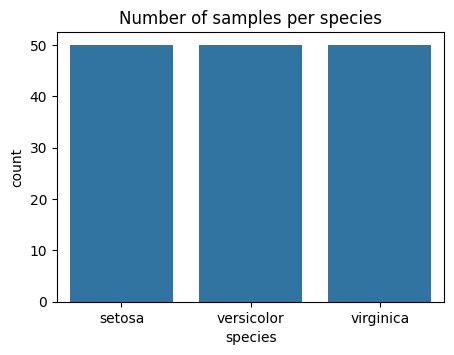

In [5]:
# %% Class distribution
print(df["species"].value_counts())
plt.figure(figsize=(5, 3.5))
sns.countplot(data=df, x="species")
plt.title("Number of samples per species")
plt.show()

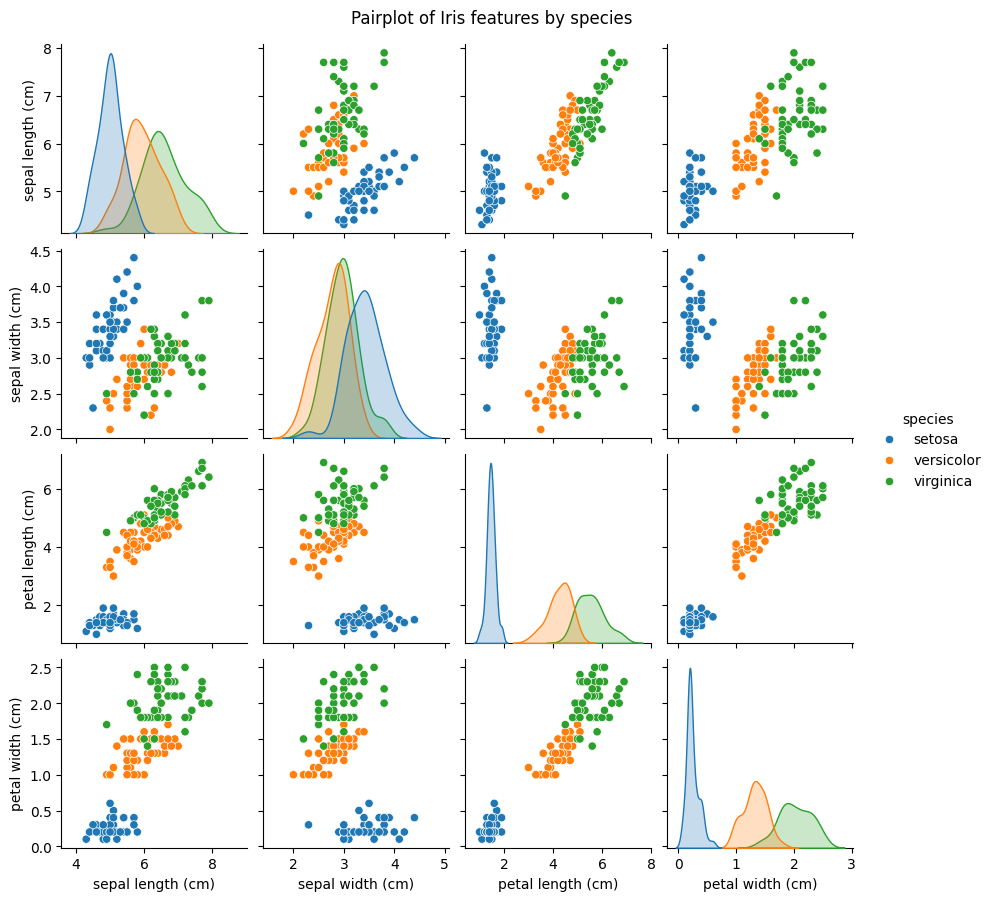

In [6]:
# %% 4a. Pairplot
sns.pairplot(df, hue="species", diag_kind="kde", height=2.2)
plt.suptitle("Pairplot of Iris features by species", y=1.02)
plt.show()

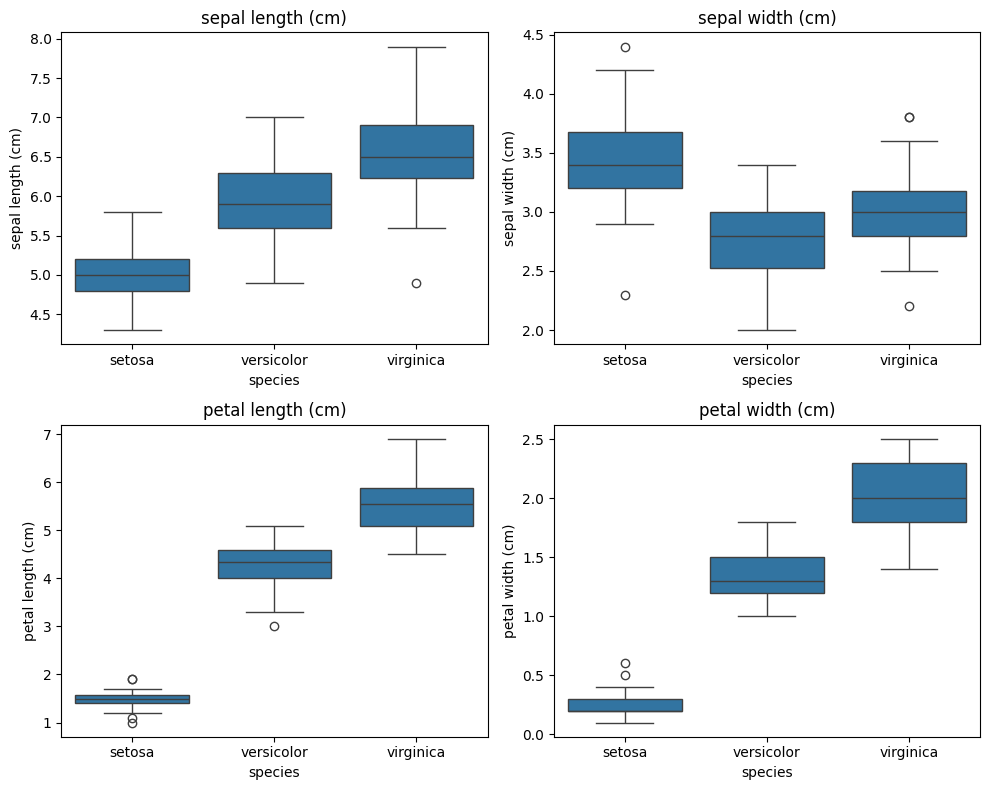

In [7]:
# %% 4b. Box plots
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, feature in zip(axes.ravel(), iris.feature_names):
    sns.boxplot(data=df, x="species", y=feature, ax=ax)
    ax.set_title(feature)
plt.tight_layout()
plt.show()

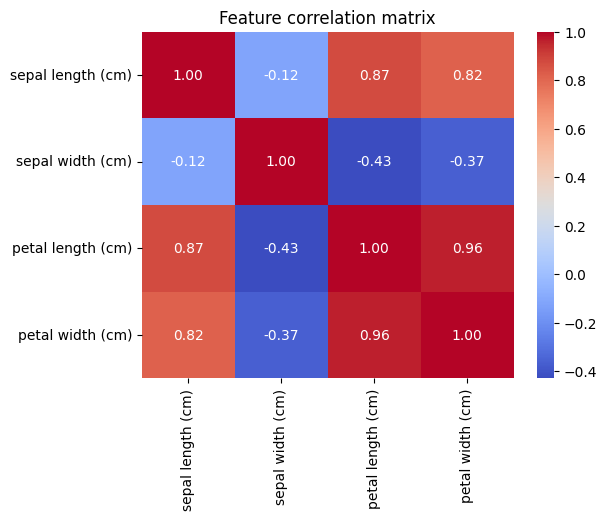

In [8]:
# %% 4c. Correlation heatmap
plt.figure(figsize=(6, 4.5))
sns.heatmap(df[iris.feature_names].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature correlation matrix")
plt.show()

In [11]:
# %% 5. Feature selection: ANOVA F-score (higher = better class separation)
F, p = f_classif(iris.data, iris.target)
fs = pd.DataFrame({"feature": iris.feature_names,
                   "F_score": F.round(1),
                   "p_value": p}).sort_values("F_score", ascending=False)
print(fs)

             feature  F_score       p_value
2  petal length (cm)   1180.2  2.856777e-91
3   petal width (cm)    960.0  4.169446e-85
0  sepal length (cm)    119.3  1.669669e-31
1   sepal width (cm)     49.2  4.492017e-17


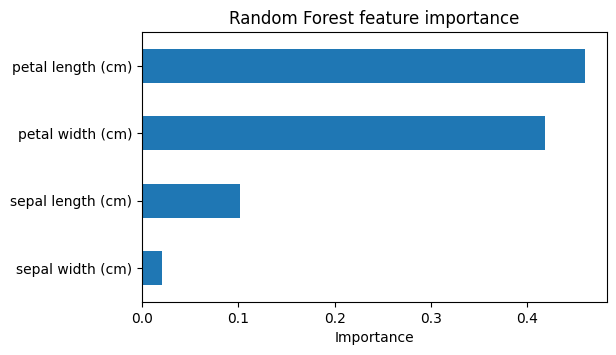

In [13]:
# %% Feature selection: Random Forest importance
rf_explore = RandomForestClassifier(n_estimators=200, random_state=42).fit(iris.data, iris.target)
imp = pd.Series(rf_explore.feature_importances_, index=iris.feature_names).sort_values()
imp.plot(kind="barh", figsize=(6, 3.5), title="Random Forest feature importance")
plt.xlabel("Importance")
plt.show()

# Discussion:
 - Petal length and petal width are the most discriminative (highest F-scores and importances).
 - Setosa is fully separated from the others on petal features.
 - Sepal width is the weakest feature (heavy overlap between species).
 - Petal length and width are highly correlated (~0.96), so they are partly redundant.
- The real challenge is Versicolor vs Virginica.

In [15]:
# %% 6. Train/test split (80/20, stratified)
X = df[iris.feature_names]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training set:", X_train.shape)
print("Test set    :", X_test.shape)

Training set: (120, 4)
Test set    : (30, 4)


In [18]:
# %% 7. Train the two classifiers
log_reg = LogisticRegression(max_iter=200, random_state=42)
rf = RandomForestClassifier(n_estimators=200, random_state=42)

log_reg.fit(X_train, y_train)
rf.fit(X_train, y_train)

models = {"Logistic Regression": log_reg, "Random Forest": rf}

In [19]:
# %% 8. Evaluation: accuracy, classification report, confusion matrix
class_names = list(iris.target_names)
results = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    results[name] = accuracy_score(y_test, y_pred)
    print("=" * 60)
    print(f"{name}  |  Test accuracy: {results[name]:.4f}")
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=class_names, digits=3))


Logistic Regression  |  Test accuracy: 0.9667
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     0.900     0.947        10
   virginica      0.909     1.000     0.952        10

    accuracy                          0.967        30
   macro avg      0.970     0.967     0.967        30
weighted avg      0.970     0.967     0.967        30

Random Forest  |  Test accuracy: 0.9000
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.818     0.900     0.857        10
   virginica      0.889     0.800     0.842        10

    accuracy                          0.900        30
   macro avg      0.902     0.900     0.900        30
weighted avg      0.902     0.900     0.900        30



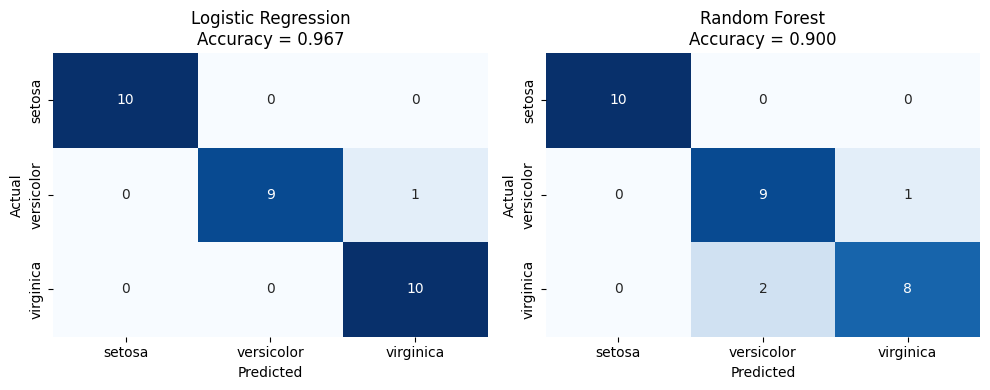

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test), labels=class_names)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f"{name}\nAccuracy = {results[name]:.3f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [22]:
# %% 9. Cross-validation (more reliable than a single 30-sample test set)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    rows.append({"Model": name,
                 "Test accuracy (80/20)": round(results[name], 4),
                 "CV mean accuracy": round(scores.mean(), 4),
                 "CV std": round(scores.std(), 4)})

summary = pd.DataFrame(rows).sort_values("CV mean accuracy", ascending=False).reset_index(drop=True)
print(summary)

                 Model  Test accuracy (80/20)  CV mean accuracy  CV std
0  Logistic Regression                 0.9667            0.9667  0.0298
1        Random Forest                 0.9000            0.9600  0.0389


In [23]:
# %% 10. Best model
best_name = summary.loc[0, "Model"]
print(f"Best model: {best_name}")
print(f"  CV accuracy       : {summary.loc[0, 'CV mean accuracy']:.4f}")
print(f"  Hold-out accuracy : {results[best_name]:.4f}")

Best model: Logistic Regression
  CV accuracy       : 0.9667
  Hold-out accuracy : 0.9667


Best model: Logistic Regression.

It has the higher test accuracy (96.7%, 1 error in 30 flowers, against 3 errors for Random Forest).
It has the higher cross-validated accuracy (96.7% against 96.0%).
It has the lower variance across folds, so it is more stable.